# The smell pathway: ORNs to Kenyon cells to MBONs

The olfactory pathway of the fly runs from the olfactory receptor neurons (`ORN_*`, 53 glomerular
types, one per antennal-lobe glomerulus) through the uniglomerular projection neurons
(`<glomerulus>_lPN`/`_adPN`/`_vPN`) to the Kenyon cells (`KC*`, the mushroom body's ~4,000-neuron
expansion layer) and on to the mushroom-body output neurons (`MBON*`, 36 types). In a real fly,
Kenyon-cell activity is famously **sparse**: in vivo, a single odor activates roughly **5-10% of
the Kenyon population** (Honegger, Campbell & Turner 2011, *Cell*; Turner, Bazhenov & Loesel 2008,
*J. Neurophysiol*).

This notebook builds odors as sets of ORN types, drives them at several strengths, and measures
what happens at each stage of that pathway in the model.

The answer is a **negative result**, and a clear one. It comes in three parts:

1. **The first relay works.** Injecting an ORN type drives its glomerular projection neurons up
   from their measured blank rest floors (0.25-0.33 fired per step, ~12-17 Hz; per-odor values in
   the resting-state cell) toward the model's 50 Hz ceiling.
2. **The Kenyon-cell layer is saturated at rest.** In the model's calibrated configuration, the
   blank runs show **4,061 of 4,064 Kenyon cells spiking in every one of the 55 measured steps**
   on the median seed (six of the eight seeds show 4,061-4,062; seed 7 manages 3,402 and seed 4
   only 1,809 -- per-seed, per-cell counts printed in the resting-state cell). The
   repository's own `notebooks/reservoir.ipynb` records the same thing ("Kenyon cells active at a
   given step: 100.0%" for the connectome), and gets chance-level (9.2%) digit readouts from
   Kenyon cells.
3. **So the smell signal vanishes at the Kenyon stage.** In seven of eight noise seeds, odor
   stimulation changes Kenyon-cell spiking by -12 to +24 net spikes across the whole
   population in the 55-step measurement window -- at most ~0.01% of the Kenyon spike-slots --
   at every strength from 0.02 V (where the PNs are still at their rest floors) to 2.0 V (above
   the ORNs' own firing ceiling); the overlap between any two odors' Kenyon "patterns" is a
   Jaccard of ~1.0; and no MBON's change survives a per-neuron test against the blank (the
   readout baseline is ~91% saturated). (Seed 4 sits on a tipping point -- see below.) The same
   odor (DM1 at 1.0 V) on a degree-preserving rewiring of the same model, whose Kenyon layer is
   *not* saturated, changes the spike counts of ~48% of the Kenyon population (against 0.05-0.07%
   on the connectome's typical seeds) -- so the flat connectome result is the wiring's, not the
   measurement's.

The model therefore does **not** reproduce the 5-10% sparse Kenyon code. We do not retune any
parameter to make it appear (the issue forbids tuning to hit the number); we show instead how the
result behaves across input strength -- two strengths at the bottom of the range (0.02 V, where
the PNs are still at their rest floor; 0.05 V, only ~0.05 above it), fine steps across the rise,
and 1.0 V, where the injected ORNs are already at 0.91 fired
per step so 2.0 V adds nothing (its per-seed Kenyon lists are identical to 1.0 V's); typical-seed
Kenyon effects stay below ~0.01% of the spike-slots throughout (never more than +24 net spikes),
and the only strong response is the tipping seed's bifurcation, not a code -- and
the saturation is a property of the real wiring: on a degree-preserving rewiring of the same model, resting Kenyon
activity drops to ~5.4% per step in this notebook's window -- measured over the same 55 steps the
sweep uses, on all eight seeds. The reservoir notebook's 18-27% for random wirings is not a
contradiction: it is a different quantity (a 100 ms decayed trace), and the cell that reproduces
it reads ~24% on these same rewired weights (see the wiring section).

**Before running:** `pip install flybrain matplotlib scipy`. The first `FlyBrain()` downloads the
brain (~260 MB) once. Everything runs on the CPU; the whole notebook takes roughly 3 minutes
(two timed full executions on this 12-thread Apple-Silicon machine: 3 min 10 s and 2 min 35 s,
machine load varying; repeated executions printed identical numbers every time).
Plots and the number tables are saved next to this notebook, in `notebooks/smell/`
(`pn_response.png`, `kc_extras.png`, `saturation_control.png`, `pn_response.csv`,
`kc_extras.csv`, `mbon_sign_test.csv`), whether it is run from `notebooks/` or from the
repository root.

**No claims about learning:** flybrain has no plasticity in the mushroom body; nothing here says
anything about odor learning, only about the feedforward sweep ORN -> PN -> KC -> MBON.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import platform

import flybrain
from flybrain import FlyBrain

# outputs go next to this notebook, whether it is run from notebooks/ or from the repo root
HERE = next(p for p in (Path.cwd(), Path.cwd() / "notebooks") if (p / "smell.ipynb").exists())
OUT = HERE / "smell"
OUT.mkdir(exist_ok=True)

# sensory_input=False removes every synapse ONTO sensory neurons. With the default True,
# ORN-to-ORN synapses pin the olfactory receptor neurons near their maximum rate at rest,
# so odours add nothing (see FlyBrain's docstring and README finding 4). The repository's
# olfactory work (notebooks/reservoir.ipynb) uses the same setting.
brain = FlyBrain(device="cpu", sensory_input=False)
ct = brain.cell_type.astype(str)

orn_types = sorted(np.unique(ct[np.char.startswith(ct, "ORN_")]))
kc = np.flatnonzero(np.char.startswith(ct, "KC"))
mbons = np.flatnonzero(np.char.startswith(ct, "MBON"))
print(f"flybrain {flybrain.__version__} on {platform.system()} ({platform.machine()}): "
      f"{brain.n:,} neurons; {len(orn_types)} ORN types, {len(kc)} Kenyon cells, "
      f"{len(np.unique(ct[mbons]))} MBON types ({len(mbons)} neurons)")

flybrain 0.1.1 on Darwin (arm64): 166,700 neurons; 53 ORN types, 4064 Kenyon cells, 36 MBON types (97 neurons)


## Odors

Three single glomeruli (`ORN_DM1`, `ORN_DL5`, `ORN_VA2`, each tens of receptor neurons on both
sides) and two seeded random mixtures (4 and 10 glomeruli). A 2 s trial (100 steps of 20 ms) with
the odor on for the middle 1 s; the injected voltage is added to every ORN of the chosen types at
every step while on. Nine strengths: **0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0 and 2.0 V per
step** -- two strengths at the bottom of the range (0.02 V: the PNs still at their rest floor;
0.05 V: ~0.05 above it), fine steps across the rise, and 2.0 V kept only to show the ceiling: at 1.0 V the injected ORNs
already fire 0.91 per step, and 2.0 V's per-seed Kenyon extras are identical to 1.0 V's. Eight
noise seeds per condition, and one matched-noise blank run per seed (same noise, no odor) so every
"extra" below is odor minus blank, not odor minus nothing. The blanks double as the resting-state
measurement: per-seed Kenyon rest activity, the count of Kenyon cells that spike in every
measured step, and each odor's projection-neuron rest floor all come from those same 8 runs.

For each odor we also name its **projection neurons** (`<glomerulus>_lPN` / `_adPN` / `_vPN`) --
the uniglomerular cells that in a real fly copy one glomerulus' ORN input to the mushroom body and
lateral horn.

In [2]:
rng = np.random.default_rng(7)
others = [t for t in orn_types if t not in ("ORN_DM1", "ORN_DL5", "ORN_VA2")]
mix4 = [others[i] for i in rng.permutation(len(others))[:4]]
mix10 = [others[i] for i in rng.permutation(len(others))[:10]]
ODORS = {"DM1": ["ORN_DM1"], "DL5": ["ORN_DL5"], "VA2": ["ORN_VA2"], "mix4": mix4, "mix10": mix10}
STRENGTHS = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 2.0]
SEEDS = list(range(8))
T, ON, TAIL = 100, (25, 75), 5          # odor on for 1 s; +5 steps of tail for propagation
WINDOW = ON[1] - ON[0] + TAIL           # 55 measured steps: the sweep's window, start to end


def pns_for(types):
    '''Uniglomerular projection neurons of a mixture's glomeruli.'''
    names = [t.removeprefix("ORN_") for t in types]
    return brain.cells([f"{g}_{s}" for g in names for s in ("lPN", "adPN", "vPN")])


def slot_of(idx):
    s = np.full(brain.n, -1, np.int64)
    s[idx] = np.arange(len(idx))
    return s


kc_slot, mbon_slot = slot_of(kc), slot_of(mbons)
mbon_ct = ct[mbons]
pn_of = {name: pns_for(types) for name, types in ODORS.items()}

for name, types in ODORS.items():
    idx = brain.cells(types)
    print(f"{name:6s}: {len(types):2d} ORN types ({len(idx):3d} neurons) -> {len(pn_of[name]):2d} uniglomerular PNs")


def trial(seed, idx, amount, pn_idx=None):
    '''One 2 s run. Per-step firing fractions over the window + tail for the injected
    ORNs, their PNs and the Kenyon cells; one full-brain spike-count array (slice it per
    population: Kenyon cells, MBONs, or any odor's projection neurons).'''
    brain.reset(seed)
    pn_idx = np.asarray(pn_idx if pn_idx is not None else [])
    orn_slot = slot_of(idx) if len(idx) else None
    pn_slot = slot_of(pn_idx) if len(pn_idx) else None
    out = {k: np.zeros(WINDOW) for k in ("orn", "pn", "kc")}
    counts = np.zeros(brain.n, np.int32)
    i = 0
    for t in range(T):
        fired = brain.step(inject=[(idx, amount)] if ON[0] <= t < ON[1] else ())
        if ON[0] <= t < ON[1] + TAIL:
            if len(fired):
                if orn_slot is not None:
                    h = orn_slot[fired]; out["orn"][i] = (h >= 0).sum() / len(idx)
                if pn_slot is not None:
                    h = pn_slot[fired]; out["pn"][i] = (h >= 0).sum() / max(1, len(pn_idx))
                h = kc_slot[fired]; out["kc"][i] = (h >= 0).sum() / len(kc)
                counts[fired] += 1
            i += 1
    return out, counts

DM1   :  1 ORN types ( 74 neurons) ->  2 uniglomerular PNs
DL5   :  1 ORN types ( 43 neurons) ->  2 uniglomerular PNs
VA2   :  1 ORN types ( 83 neurons) ->  2 uniglomerular PNs
mix4  :  4 ORN types (252 neurons) -> 16 uniglomerular PNs
mix10 : 10 ORN types (436 neurons) -> 43 uniglomerular PNs


## First, the resting state

Before any odor: how active is each stage? The 8 blank runs (one per seed, matched noise, no odor)
answer every rest question in this notebook at once: the Kenyon rest fraction per seed, the number
of Kenyon cells that spike in **every one of the 55 measured steps** (a per-cell count, not a
mean over steps), and each odor's projection-neuron rest floor, read from the same full-brain
spike counts. These same runs are the blanks every "extra" below is measured against, so nothing
is measured twice.

In [3]:
t0 = time.time()
blank = {seed: trial(seed, np.empty(0, np.int64), 0.0) for seed in SEEDS}
print(f"{len(blank)} blank (rest) runs in {(time.time() - t0) / 60:.2f} min")
kc_frac = np.array([blank[s][0]["kc"].mean() for s in SEEDS])
print("Kenyon cells at rest, per seed:")
for s in SEEDS:
    every = int((blank[s][1][kc] == WINDOW).sum())
    print(f"  seed {s}: {100 * kc_frac[s]:6.2f}% fire per step; "
          f"{every} of {len(kc)} ({100 * every / len(kc):.2f}%) spike in all {WINDOW} steps")
print(f"median seed: {100 * np.median(kc_frac):.2f}% per step")
print("projection-neuron rest floors (fired/step, mean over seeds, from the same 8 runs):")
pn_floor = {}
for name in ODORS:
    pn_floor[name] = float(np.mean([blank[s][1][pn_of[name]].mean() / WINDOW for s in SEEDS]))
    print(f"  {name:6s}: {pn_floor[name]:.3f} per step  (~{50 * pn_floor[name]:.1f} Hz, "
          f"{len(pn_of[name])} PNs)")
spikes = [len(brain.step()) for _ in range(20)]
print(f"whole-brain spikes per step at rest: ~{np.mean(spikes):.0f}")

8 blank (rest) runs in 0.06 min
Kenyon cells at rest, per seed:
  seed 0:  99.97% fire per step; 4061 of 4064 (99.93%) spike in all 55 steps
  seed 1:  99.97% fire per step; 4062 of 4064 (99.95%) spike in all 55 steps
  seed 2:  99.97% fire per step; 4061 of 4064 (99.93%) spike in all 55 steps
  seed 3:  99.97% fire per step; 4061 of 4064 (99.93%) spike in all 55 steps
  seed 4:  93.02% fire per step; 1809 of 4064 (44.51%) spike in all 55 steps
  seed 5:  99.97% fire per step; 4061 of 4064 (99.93%) spike in all 55 steps
  seed 6:  99.97% fire per step; 4061 of 4064 (99.93%) spike in all 55 steps
  seed 7:  99.60% fire per step; 3402 of 4064 (83.71%) spike in all 55 steps
median seed: 99.97% per step
projection-neuron rest floors (fired/step, mean over seeds, from the same 8 runs):
  DM1   : 0.326 per step  (~16.3 Hz, 2 PNs)
  DL5   : 0.332 per step  (~16.6 Hz, 2 PNs)
  VA2   : 0.249 per step  (~12.4 Hz, 2 PNs)
  mix4  : 0.275 per step  (~13.8 Hz, 16 PNs)
  mix10 : 0.300 per step  (~15.

## Run the odor sweep

Five odors x nine strengths x eight seeds, each measured against its matched-noise blank from the
cell above.

In [4]:
t0 = time.time()
res = {}
for name, types in ODORS.items():
    idx = brain.cells(types)
    for a in STRENGTHS:
        for seed in SEEDS:
            res[name, a, seed] = trial(seed, idx, a, pn_of[name])
print(f"{len(res)} odor runs (+{len(blank)} blanks) in {(time.time() - t0) / 60:.1f} min")

360 odor runs (+8 blanks) in 1.7 min


## The first relay works: projection neurons

Injected ORNs follow the drive, and their uniglomerular projection neurons follow them -- once the
drive is strong enough to leave the rest floor. The blanks put that floor at 0.25-0.33 fired/step
(~12-17 Hz; the table's blank rows are each odor's own projection neurons, measured in the
resting-state cell): at 0.02 V the PN rate is still within ~0.015 of its floor, and at 0.05 V it
has lifted only ~0.04-0.06 above it -- which is why strengths below 0.1 V are in the sweep; from
0.1 V the odor's glomeruli rise more clearly (0.37-0.44 per step, ~0.1 above their floors); the
mid range is not monotonic -- DM1's PN rate steps through ~0.43, ~0.50, ~0.56, ~0.48, ~0.53 at
0.1-0.7 V, and the other odors behave similarly (regime changes in how often the ORNs fire, not a
smooth curve) -- so the sweep samples it finely; and from 1.0 V on the rate pins near the
one-spike-per-step ceiling (0.92-0.93 per step, ~46-47 Hz), where the injected ORNs themselves fire 0.91
per step. Whatever the exact shape, the signal crosses ORN -> PN strongly, on the odor's own
glomeruli.

In [5]:
import csv

pn_rows = []
print(f"{'odor':6s} {'V/step':>6s} {'ORN fired/step':>15s} {'PN fired/step':>17s}")
for name in ODORS:
    for a in STRENGTHS:
        orn = np.array([res[name, a, s][0]["orn"].mean() for s in SEEDS])
        pn = np.array([res[name, a, s][0]["pn"].mean() for s in SEEDS])
        print(f"{name:6s} {a:6.2f} {orn.mean():9.2f}±{orn.std(ddof=1):5.2f} "
              f"{pn.mean():11.2f}±{pn.std(ddof=1):5.2f}")
        pn_rows.append((name, a, orn.mean(), orn.std(ddof=1), pn.mean(), pn.std(ddof=1)))
print("blank (rest), each odor's own PNs, from the same 8 blank runs:")
for name in ODORS:
    print(f"  {name:6s} {pn_floor[name]:.3f} per step  (~{50 * pn_floor[name]:.1f} Hz)")
with open(OUT / "pn_response.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["odor", "v_per_step", "orn_per_step_mean", "orn_per_step_sd",
                "pn_per_step_mean", "pn_per_step_sd"])
    w.writerows([(n, a, round(o, 4), round(os_, 4), round(p, 4), round(ps, 4))
                 for n, a, o, os_, p, ps in pn_rows])
print("saved", OUT / "pn_response.csv")

odor   V/step  ORN fired/step     PN fired/step
DM1      0.02      0.02± 0.00        0.34± 0.00
DM1      0.05      0.06± 0.00        0.37± 0.01
DM1      0.10      0.12± 0.00        0.43± 0.01
DM1      0.20      0.24± 0.00        0.50± 0.01
DM1      0.30      0.31± 0.00        0.56± 0.03
DM1      0.50      0.45± 0.00        0.48± 0.00
DM1      0.70      0.46± 0.00        0.53± 0.04
DM1      1.00      0.91± 0.00        0.93± 0.00
DM1      2.00      0.91± 0.00        0.93± 0.00
DL5      0.02      0.02± 0.00        0.34± 0.01
DL5      0.05      0.06± 0.00        0.38± 0.01
DL5      0.10      0.12± 0.00        0.44± 0.02
DL5      0.20      0.24± 0.00        0.51± 0.02
DL5      0.30      0.31± 0.00        0.56± 0.04
DL5      0.50      0.45± 0.00        0.48± 0.01
DL5      0.70      0.46± 0.00        0.55± 0.06
DL5      1.00      0.91± 0.00        0.93± 0.01
DL5      2.00      0.91± 0.00        0.93± 0.01
VA2      0.02      0.02± 0.00        0.26± 0.01
VA2      0.05      0.06± 0.00        0.3

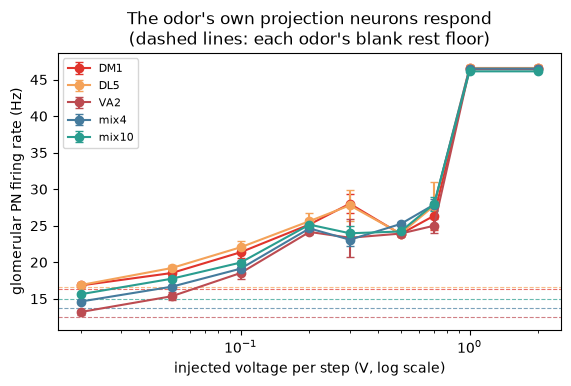

saved /Users/thescoho/.treehouse/fly.ai-e22435/4/fly.ai/notebooks/smell/pn_response.png


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, color in zip(ODORS, ("#e0342c", "#f4a259", "#bc4b51", "#457b9d", "#2a9d8f")):
    pn = [np.mean([res[name, a, s][0]["pn"].mean() for s in SEEDS]) * 50 for a in STRENGTHS]
    sd = [np.std([res[name, a, s][0]["pn"].mean() for s in SEEDS], ddof=1) * 50 for a in STRENGTHS]
    ax.errorbar(STRENGTHS, pn, yerr=sd, marker="o", capsize=3, color=color, label=name)
    ax.axhline(pn_floor[name] * 50, ls="--", c=color, lw=0.8, alpha=0.7)
ax.set_xscale("log")
ax.set_xlabel("injected voltage per step (V, log scale)")
ax.set_ylabel("glomerular PN firing rate (Hz)")
ax.set_title("The odor's own projection neurons respond\n(dashed lines: each odor's blank rest floor)")
ax.legend(fontsize=8)
plt.savefig(OUT / "pn_response.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", OUT / "pn_response.png")

## The Kenyon layer: saturated, so the odor adds nothing

Now the measurement the issue asks for: **the fraction of Kenyon cells that spike**. Over the
55-step measurement window the answer is ~100% for every odor and every strength on seven of the
eight seeds (the blank too), and the resting-state cell above shows why: on six of the eight
seeds, 4,061-4,062 of 4,064 Kenyon cells spike in all 55 measured steps (seed 7: 3,402; seed 4:
1,809 -- per-seed, per-cell counts printed there). "Fraction that spikes" cannot separate an odor from no odor. The informative number is
the **odor-attributable** spiking: Kenyon spikes in the stimulus run minus the matched-noise
blank run, per seed.

For **seven of the eight seeds the net effect is tiny at every strength**: per-seed net extras
of -12 to +24 spikes (medians -4 to +17) in a window that contains ~223,520 Kenyon spike-slots
(4,064 neurons x 55 steps) -- at most ~0.011% of the spike-slots; at 1.0 V and above, DM1, VA2
and mix10 gain consistently across those seeds, but never more than those ~24 spikes. The cell
below also prints, per seed, the largest number
of Kenyon cells that gain even one spike in any condition: 2-6 cells on the seven typical seeds
(seed 4: 1,957) -- the direct per-cell counterpart of the net numbers. **Seed 4 sits on a tipping point instead**: in that noise trajectory the blank
run's Kenyon layer settles at ~93% per step rather than ~100%, and the odor tips it over (the
cell further below identifies the seed and measures exactly what tips). The layer is metastable between
nearly-saturated regimes, not stably sparse. In the in-vivo literature, 5-10% of Kenyon cells
*respond* to an odor; the per-seed gainers printed below are the model's side of that
comparison, on a population that is ~100% active before the odor arrives.

In [7]:
print(f"{'odor':6s} {'V/step':>6s} {'extra KC spikes, per seed':>34s} {'median':>7s} {'max':>6s}")
kc_rows = []
for name in ODORS:
    for a in STRENGTHS:
        extra = np.stack([res[name, a, s][1][kc] - blank[s][1][kc] for s in SEEDS])
        tot = extra.sum(1)
        print(f"{name:6s} {a:6.2f} {str(tot.tolist()):>34s} {np.median(tot):7.0f} {tot.max():6.0f}")
        kc_rows.append([name, a] + tot.tolist() + [float(np.median(tot)), float(tot.max())])
gainers = [max(int(((res[name, a, s][1][kc] - blank[s][1][kc]) > 0).sum())
               for name in ODORS for a in STRENGTHS) for s in SEEDS]
print(f"largest count of Kenyon cells gaining >= 1 spike in any odor x strength, per seed: {gainers}")
with open(OUT / "kc_extras.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["odor", "v_per_step"] + [f"seed{s}" for s in SEEDS] + ["median", "max"])
    w.writerows(kc_rows)
print("saved", OUT / "kc_extras.csv")

odor   V/step          extra KC spikes, per seed  median    max
DM1      0.02      [1, -6, -4, 0, 44, -3, 0, -2]      -1     44
DM1      0.05      [2, 1, -1, 5, 131, -3, 2, -3]       2    131
DM1      0.10     [5, -2, 3, 13, 376, 6, -4, -1]       4    376
DM1      0.20        [4, 1, 6, 9, 612, 12, 0, 3]       5    612
DM1      0.30       [3, 2, 5, 15, 772, 13, 0, 5]       5    772
DM1      0.50         [4, 1, 4, 3, 918, 4, 1, 7]       4    918
DM1      0.70        [5, 2, 5, 7, 920, 12, 2, 4]       5    920
DM1      1.00 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DM1      2.00 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DL5      0.02       [1, -5, 1, 2, 43, -6, -1, 2]       1     43
DL5      0.05     [4, -3, -6, 1, 105, 0, -8, -3]      -2    105
DL5      0.10    [-3, -3, -7, 4, 133, -1, 1, -2]      -2    133
DL5      0.20      [-1, -2, 2, 1, 327, 8, 3, -6]       2    327
DL5      0.30    [2, -9, -4, -3, 337, 5, -6, -4]      -4    337
DL5      0.50     [-3, -3, -1, 4, 550, 4

largest count of Kenyon cells gaining >= 1 spike in any odor x strength, per seed: [3, 2, 3, 3, 1957, 3, 3, 6]
saved /Users/thescoho/.treehouse/fly.ai-e22435/4/fly.ai/notebooks/smell/kc_extras.csv


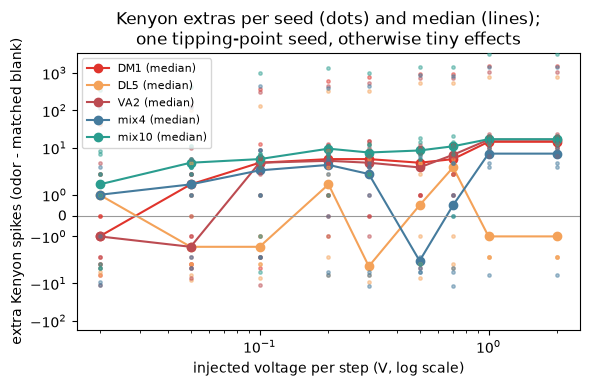

saved /Users/thescoho/.treehouse/fly.ai-e22435/4/fly.ai/notebooks/smell/kc_extras.png


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, color in zip(ODORS, ("#e0342c", "#f4a259", "#bc4b51", "#457b9d", "#2a9d8f")):
    tot = np.stack([np.stack([res[name, a, s][1][kc] - blank[s][1][kc] for s in SEEDS]).sum(1)
                    for a in STRENGTHS])          # (strength, seed)
    ax.plot(STRENGTHS, np.median(tot, 1), marker="o", color=color, label=f"{name} (median)")
    ax.scatter(np.repeat(STRENGTHS, len(SEEDS)), tot.ravel(), s=6, color=color, alpha=0.45,
               zorder=3)
ax.axhline(0, c="0.6", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("symlog")
ax.set_xlabel("injected voltage per step (V, log scale)")
ax.set_ylabel("extra Kenyon spikes (odor - matched blank)")
ax.set_title("Kenyon extras per seed (dots) and median (lines);\none tipping-point seed, otherwise tiny effects")
ax.legend(fontsize=8)
plt.savefig(OUT / "kc_extras.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", OUT / "kc_extras.png")

### Overlap between odors

Two different odors should activate different Kenyon subsets; in vivo their patterns overlap only
weakly. Here the "pattern" of every odor is the same ~all-Kenyon set the blank produces, so the
Jaccard overlap of any two odors' Kenyon spike sets is ~1.0 -- the set contains no odor
information at all.

In [9]:
names = list(ODORS)
print(f"Jaccard overlap of Kenyon spike sets at 1.0 V (mean over {len(SEEDS)} seeds):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        ov = []
        for s in SEEDS:
            a = res[names[i], 1.0, s][1][kc] > 0
            b = res[names[j], 1.0, s][1][kc] > 0
            union = (a | b).sum()
            ov.append((a & b).sum() / union if union else np.nan)
        print(f"  {names[i]:6s} vs {names[j]:6s}: {np.mean(ov):.3f}")

Jaccard overlap of Kenyon spike sets at 1.0 V (mean over 8 seeds):
  DM1    vs DL5   : 1.000
  DM1    vs VA2   : 1.000
  DM1    vs mix4  : 1.000
  DM1    vs mix10 : 1.000
  DL5    vs VA2   : 1.000
  DL5    vs mix4  : 1.000
  DL5    vs mix10 : 1.000
  VA2    vs mix4  : 1.000
  VA2    vs mix10 : 1.000
  mix4   vs mix10 : 1.000


### The tipping-point seed, isolated

The `max` column above is one seed, not a typical response. Here it is, measured directly.

In [10]:
best = max(((name, a, seed, res[name, a, seed][1][kc] - blank[seed][1][kc])
             for name in ODORS for a in STRENGTHS for seed in SEEDS),
            key=lambda r: r[3].sum())
name, a, seed, extra = best
frac_blank = blank[seed][0]["kc"].mean()
frac_stim = res[name, a, seed][0]["kc"].mean()
print(f"largest odor effect in the whole sweep: odor {name} at {a:.2f} V/step, seed {seed}")
print(f"  that seed's blank run:   {100 * frac_blank:.2f}% of Kenyon cells fire per step")
print(f"  that seed's odor run:    {100 * frac_stim:.2f}% of Kenyon cells fire per step")
print(f"  extra spikes (odor - blank): {int(extra.sum())} across the {WINDOW}-step window")
print(f"  Kenyon cells gaining >= 1 spike: {(extra > 0).sum()} of {len(kc)} "
      f"({100 * (extra > 0).mean():.1f}%)")
print(f"  all other seeds, same condition: "
      f"{[int((res[name, a, s][1][kc] - blank[s][1][kc]).sum()) for s in SEEDS if s != seed]}")

largest odor effect in the whole sweep: odor mix10 at 1.00 V/step, seed 4
  that seed's blank run:   93.02% of Kenyon cells fire per step
  that seed's odor run:    94.49% of Kenyon cells fire per step
  extra spikes (odor - blank): 3277 across the 55-step window
  Kenyon cells gaining >= 1 spike: 1957 of 4064 (48.2%)
  all other seeds, same condition: [17, 16, 13, 18, 21, 17, 17]


## MBONs: which output neurons respond to which odors?

Mushroom-body output neurons receive the Kenyon cells -- and at rest they are **also nearly
saturated** (about 91% of MBON spike-slots are used before any odor). The honest way to ask which
MBONs respond to which odors is a **per-neuron test**, not a scan for the biggest-looking cell:
for every odor at every strength, each of the 97 MBON neurons is tested separately -- its
odor-minus-blank extra spikes across the 8 seeds, sign test, then Holm correction for testing 97
neurons at once. With 8 seeds even a neuron gaining spikes in all 8 seeds could not pass that
correction (best possible Holm-adjusted p = 97 x 2^-7 ~ 0.76), and nothing here comes close. **No
MBON's change is distinguishable from noise at any odor or strength.** Descriptively, the largest
median gain at 1.0 V is +2.5 spikes over the 55-step window (0 to +5 per seed) on a baseline that
is already ~91% saturated -- far from the tens of spikes per second an odor evokes in a real
fly's MBONs.

In [11]:
from scipy.stats import binomtest

blank_mbon = np.stack([blank[s][1][mbons] for s in SEEDS])
print(f"MBON spikes at rest: {blank_mbon.sum(1).mean():.0f} over the window across {len(mbons)} "
      f"neurons = {100 * blank_mbon.sum(1).mean() / (len(mbons) * WINDOW):.0f}% of MBON spike-slots")
print("per-MBON sign test on odor-minus-blank extras across the 8 seeds")
print("(two-sided, Holm-corrected over the 97 MBON neurons within each odor x strength):")


def holm(p):
    order = np.argsort(p, kind="stable")
    adj = np.empty(len(p))
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(run, 1.0)
    return adj


n_sig, best, sig_rows = 0, None, []
for name in ODORS:
    for a in STRENGTHS:
        extra = np.stack([res[name, a, s][1][mbons] - blank[s][1][mbons] for s in SEEDS])
        pos, neg = (extra > 0).sum(0), (extra < 0).sum(0)
        n = pos + neg
        p = np.array([binomtest(pos[i], n[i], 0.5).pvalue if n[i] else 1.0
                      for i in range(len(mbons))])
        adj = holm(p)
        n_sig += int((adj < 0.05).sum())
        i = int(np.argmin(p))
        sig_rows.append([name, a, int((adj < 0.05).sum()), int(pos[i]), int(n[i]), float(p[i])])
        if best is None or p[i] < best[0]:
            best = (float(p[i]), name, a, i, int(pos[i]), int(n[i]), extra[:, i].copy())
print(f"  tests run: {len(ODORS) * len(STRENGTHS) * len(mbons)}; "
      f"passing the corrected test: {n_sig}")
p0, name, a, i, pos, n, ex = best
print(f"  strongest raw case (not significant after correction): {mbon_ct[i]}[{i}] "
      f"for {name} at {a:.2f} V; per-seed extras {ex.tolist()}; +ve in {pos}/{n} seeds, "
      f"raw p = {p0:.3f}")
meds = {nm: np.median(np.stack([res[nm, 1.0, s][1][mbons] - blank[s][1][mbons] for s in SEEDS]), 0)
        for nm in ODORS}
nm = max(meds, key=lambda k: meds[k].max())
j = int(np.argmax(meds[nm]))
ex = np.stack([res[nm, 1.0, s][1][mbons] - blank[s][1][mbons] for s in SEEDS])[:, j]
print(f"  largest median gain at 1.0 V (descriptive): {mbon_ct[j]}[{j}] for {nm}, "
      f"median {np.median(ex):+.1f} spikes, per-seed extras {ex.tolist()}")
with open(OUT / "mbon_sign_test.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["odor", "v_per_step", "n_significant", "best_pos", "best_n", "best_raw_p"])
    w.writerows(sig_rows)
print("saved", OUT / "mbon_sign_test.csv")

MBON spikes at rest: 4853 over the window across 97 neurons = 91% of MBON spike-slots
per-MBON sign test on odor-minus-blank extras across the 8 seeds
(two-sided, Holm-corrected over the 97 MBON neurons within each odor x strength):
  tests run: 4365; passing the corrected test: 0
  strongest raw case (not significant after correction): MBON10[48] for VA2 at 0.30 V; per-seed extras [0, 1, 3, 1, 1, 1, 1, 2]; +ve in 7/7 seeds, raw p = 0.016


  largest median gain at 1.0 V (descriptive): MBON10[48] for VA2, median +2.5 spikes, per-seed extras [1, 2, 2, 3, 3, 0, 5, 5]
saved /Users/thescoho/.treehouse/fly.ai-e22435/4/fly.ai/notebooks/smell/mbon_sign_test.csv


## Is the saturation the wiring's fault?

The Kenyon cells being pinned at the ceiling is a property of the **real connectome's** recurrent
drive in this model recipe, not of the recipe alone: the repository's `notebooks/reservoir.ipynb`
records Kenyon activity of 100% for the connectome and much lower for random rewirings of the
same model. We reproduce that control here over all eight seeds (tipping seed included), with a
degree-preserving rewiring: every neuron keeps its in- and out-degree and its synaptic signs; who
connects to whom is random, and incoming weight strengths are rescaled to match. The control
settles for 25 steps and then measures the **same 55-step window the sweep uses** -- the procedure
is identical to the blank runs, so the connectome row below matches the resting-state cell
exactly, seed for seed.

**Why the rewired number here is lower than the reservoir notebook's 18-27%: the two notebooks
report different quantities.** The reservoir's "Kenyon cells active at a given step" is a 100 ms
decayed trace (`tau = 0.1`) read against a 0.5 threshold -- a single spike holds the decaying
trace above 0.5 for four consecutive step-readings (decay `exp(-0.02/0.1)` per step), so a cell
counts as active if it has spiked within roughly the last three steps (the reservoir's own gloss:
"100% spiked within the last 3 steps"). This notebook reports the per-step spike fraction, a
strictly tighter measure. The last cell below measures the reservoir's quantity on these same
rewired weights, same seeds, same window: it reads ~24%, inside the reservoir's 18-27% band,
while the per-step fraction reads ~5.4%. (The reservoir's band pools its two random-wiring
families in a driven digit-stream regime -- its degree-preserving shuffle reads 25.9-27.0% there,
its Erdős–Rényi 18.6-18.7% -- and even at rest, on this single degree-preserving rewiring, its
measure lands in the same pooled band.) There is no contradiction to explain away: both measures
agree the real wiring saturates the Kenyon layer and random wiring does not.

(Swapping the weight matrix uses `FlyBrain`'s internal arrays, exactly as `reservoir.ipynb` does;
it is a notebook trick, not a public API.)

resting Kenyon cells firing per step, per seed (settle 25, measure 55 -- the sweep's window):
  connectome: ['99.97', '99.97', '99.97', '99.97', '93.02', '99.97', '99.97', '99.60']
  blank runs: ['99.97', '99.97', '99.97', '99.97', '93.02', '99.97', '99.97', '99.60'] (same procedure, resting-state cell)
  rewired:    ['5.3', '5.4', '5.5', '5.3', '5.4', '5.4', '5.4', '5.5']
means: connectome 99.1% ± 2.4, degree-preserving rewiring 5.4% ± 0.1
connectome row vs the blank runs (identical procedure): max per-seed difference 1.1e-16


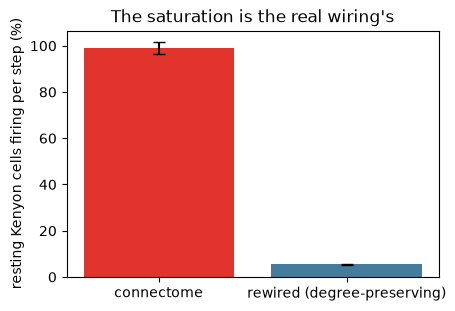

saved /Users/thescoho/.treehouse/fly.ai-e22435/4/fly.ai/notebooks/smell/saturation_control.png


In [12]:
from scipy import sparse

original = sparse.csc_matrix((brain.weights, brain.indices, brain.indptr), shape=(brain.n, brain.n)).tocsr()
row_strength = np.asarray(abs(original).sum(1)).ravel()


def match_input_strength(W):
    W = W.tocsr()
    W.sum_duplicates()
    s = np.asarray(abs(W).sum(1)).ravel()
    scale = np.divide(row_strength, s, out=np.zeros_like(s), where=s > 0)
    W = sparse.diags(scale.astype(np.float32)) @ W
    W.eliminate_zeros()
    return W.tocsr()


coo = original.tocoo()
post = np.random.default_rng(11).permutation(coo.row)
shuffled = match_input_strength(sparse.coo_matrix((coo.data, (post, coo.col)), shape=original.shape))


def use_weights(W):
    W = W.tocsr().astype(np.float32)
    W.sort_indices()
    csc = W.tocsc()
    brain.indptr, brain.indices, brain.weights = csc.indptr, csc.indices, csc.data


def rest_kc_fraction(seeds, settle=25, steps=WINDOW):
    '''The same window the sweep uses: settle for 25 steps, then measure WINDOW steps.'''
    fr = []
    for seed in seeds:
        brain.reset(seed)
        for _ in range(settle):
            brain.step()
        c = 0
        for _ in range(steps):
            fired = brain.step()
            c += (kc_slot[fired] >= 0).sum() if len(fired) else 0
        fr.append(c / (steps * len(kc)))
    return np.array(fr)


frac_real = rest_kc_fraction(SEEDS)
use_weights(shuffled)
frac_shuffled = rest_kc_fraction(SEEDS)
use_weights(original)
print("resting Kenyon cells firing per step, per seed (settle 25, measure 55 -- the sweep's window):")
print("  connectome:", [f"{100 * v:.2f}" for v in frac_real])
print("  blank runs:", [f"{100 * v:.2f}" for v in kc_frac], "(same procedure, resting-state cell)")
print("  rewired:   ", [f"{100 * v:.1f}" for v in frac_shuffled])
print(f"means: connectome {100 * frac_real.mean():.1f}% ± {100 * frac_real.std(ddof=1):.1f}, "
      f"degree-preserving rewiring {100 * frac_shuffled.mean():.1f}% "
      f"± {100 * frac_shuffled.std(ddof=1):.1f}")
print(f"connectome row vs the blank runs (identical procedure): "
      f"max per-seed difference {np.abs(frac_real - kc_frac).max():.1e}")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar([0, 1], [100 * frac_real.mean(), 100 * frac_shuffled.mean()],
       yerr=[100 * frac_real.std(ddof=1), 100 * frac_shuffled.std(ddof=1)], capsize=4,
       color=["#e0342c", "#457b9d"])
ax.set_xticks([0, 1], ["connectome", "rewired (degree-preserving)"])
ax.set_ylabel("resting Kenyon cells firing per step (%)")
ax.set_title("The saturation is the real wiring's")
plt.savefig(OUT / "saturation_control.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", OUT / "saturation_control.png")

In [13]:
from flybrain import Trace


def trace_kc_fraction(W, seeds, settle=25, steps=WINDOW):
    '''The reservoir notebook's measure, on the same weights: a 100 ms decayed trace
    (tau = 0.1); a Kenyon cell counts as active when its trace exceeds 0.5.'''
    use_weights(W)
    tr = Trace(brain, idx=kc, tau=0.1)
    fr = []
    for seed in seeds:
        brain.reset(seed)
        tr.reset()
        for _ in range(settle):
            tr.observe(brain.step())
        c = 0
        for _ in range(steps):
            tr.observe(brain.step())
            c += (tr.features() > 0.5).sum()
        fr.append(c / (steps * len(kc)))
    return np.array(fr)


tr_real = trace_kc_fraction(original, SEEDS)
tr_shuffled = trace_kc_fraction(shuffled, SEEDS)
use_weights(original)
print("the reservoir's own measure (trace tau = 0.1, active = trace > 0.5),")
print("same weights, seeds and window as the control above:")
print(f"  connectome: {100 * tr_real.mean():.1f}% ± {100 * tr_real.std(ddof=1):.1f} "
      f"(reservoir.ipynb records 100.0%)")
print(f"  rewired:   {100 * tr_shuffled.mean():.1f}% ± {100 * tr_shuffled.std(ddof=1):.1f} "
      f"(reservoir.ipynb records 18-27% for random wirings)")
print(f"  the same rewired runs, per-step spike fraction: "
      f"{100 * frac_shuffled.mean():.1f}% ± {100 * frac_shuffled.std(ddof=1):.1f}")

the reservoir's own measure (trace tau = 0.1, active = trace > 0.5),
same weights, seeds and window as the control above:
  connectome: 99.2% ± 2.2 (reservoir.ipynb records 100.0%)
  rewired:   24.4% ± 0.3 (reservoir.ipynb records 18-27% for random wirings)
  the same rewired runs, per-step spike fraction: 5.4% ± 0.1


## The same odor on the rewired brain

The connectome's Kenyon layer is saturated, so the odor has nothing to move there. On the
degree-preserving rewiring the layer is *not* saturated (~5.4% at rest) -- if the odor reaches
Kenyon cells at all, it should be visible there. This is the control that shows the flat
connectome result is the wiring's, not a blind spot of the measurement: the same odor (DM1 at
1.0 V), the same injection, the same matched-noise subtraction, on the rewired weights, for
**all eight seeds** (tipping seed included). The table also prints the connectome's own numbers
for the same condition, with the same "spike count changed at all" column: the connectome sits at
0.05-0.07% on its typical seeds, against 47.5-49.1% on the rewired brain. (On a network sitting near its firing threshold the net change can be
small while many cells are touched, so read both columns: the net extra spikes *and* the fraction
of Kenyon cells whose spike count changed.)

In [14]:
rewired_runs = {}
use_weights(shuffled)
for seed in SEEDS:
    stim = trial(seed, brain.cells(["ORN_DM1"]), 1.0, pns_for(["ORN_DM1"]))
    blank_r = trial(seed, np.empty(0, np.int64), 0.0)
    rewired_runs[seed] = stim, blank_r
use_weights(original)

print(f"{'seed':>4s} {'KC blank/step':>13s} {'KC odor/step':>12s} {'extra KC spikes':>15s} {'KCs changed':>11s}")
for seed, (stim, blank_r) in rewired_runs.items():
    extra = stim[1][kc] - blank_r[1][kc]
    print(f"{seed:4d} {100 * blank_r[0]['kc'].mean():12.1f}% {100 * stim[0]['kc'].mean():11.1f}% "
          f"{int(extra.sum()):15d} {100 * (extra != 0).mean():10.1f}%")
conn = [(int((res['DM1', 1.0, s][1][kc] - blank[s][1][kc]).sum()),
         100 * (res['DM1', 1.0, s][1][kc] - blank[s][1][kc] != 0).mean()) for s in SEEDS]
print("same odor (DM1 at 1.0 V) on the connectome, same seeds:")
for s, (net, moved) in zip(SEEDS, conn):
    print(f"  seed {s}: net extras {net:+5d}; Kenyon cells with any change {moved:.2f}%")

seed KC blank/step KC odor/step extra KC spikes KCs changed
   0          5.3%         5.4%             244       48.5%
   1          5.4%         5.4%             -62       47.5%
   2          5.5%         5.6%             164       48.0%
   3          5.3%         5.4%              41       48.2%
   4          5.4%         5.5%             101       49.1%
   5          5.4%         5.5%             102       47.8%
   6          5.4%         5.4%              70       49.1%
   7          5.5%         5.5%             199       48.6%
same odor (DM1 at 1.0 V) on the connectome, same seeds:
  seed 0: net extras   +11; Kenyon cells with any change 0.07%
  seed 1: net extras   +13; Kenyon cells with any change 0.05%
  seed 2: net extras   +14; Kenyon cells with any change 0.07%
  seed 3: net extras   +20; Kenyon cells with any change 0.05%
  seed 4: net extras +1555; Kenyon cells with any change 26.65%
  seed 5: net extras   +21; Kenyon cells with any change 0.07%
  seed 6: net extras   +1

## What the ORN-to-ORN runaway would have added

With `sensory_input=True` (the default), the ORN-to-ORN synapses pin the receptor neurons near
their maximum rate at rest, so odors add nothing even at the *input* stage (README finding 4). We
verify that quickly here, then continue with the `sensory_input=False` brain used above:

In [15]:
brain2 = FlyBrain(device="cpu", sensory_input=True)
ct2 = brain2.cell_type.astype(str)
orn_all = np.flatnonzero(np.char.startswith(ct2, "ORN_"))
orn_slot2 = np.full(brain2.n, -1, np.int64)
orn_slot2[orn_all] = np.arange(len(orn_all))
brain2.reset(0)
for _ in range(10):
    brain2.step()
c = 0
for _ in range(30):
    fired = brain2.step()
    c += (orn_slot2[fired] >= 0).sum() if len(fired) else 0
print(f"ORN firing per step with sensory_input=True: {100 * c / (30 * len(orn_all)):.0f}% "
      f"(pinned by ORN-to-ORN synapses; see README finding 4)")
del brain2

ORN firing per step with sensory_input=True: 50% (pinned by ORN-to-ORN synapses; see README finding 4)


## Summary

* **Fraction of Kenyon cells that spike: ~100%, for every odor and every strength (0.02-2.0
  V/step) on seven of eight seeds, and with no odor at all.** The Kenyon layer of this model sits at (or a whisker from) the 50 Hz
  ceiling at rest -- on six of the eight seeds, 4,061-4,062 of 4,064 Kenyon cells spike in every
  one of the 55 measured blank steps (seed 7: 3,402; seed 4: 1,809) -- so the sparseness measure cannot even in principle separate odors. One
  seed in eight settles at ~93% instead of ~100%: the layer is metastable between near-saturated
  regimes, and the only sizable odor effect in the whole notebook is that seed tipping over.
* **Odor-attributable Kenyon spiking: tiny at every strength** -- per-seed net extras of -12 to +24
  spikes (medians -4 to +17) across 4,064 neurons in the 55-step window, at every strength from
  0.02 V (where the PNs are still at their rest floors) to 2.0 V (above the ORNs' own ceiling).
  The largest number of Kenyon cells gaining even one spike in any condition, per seed: 2-6
  cells on the seven typical seeds, 1,957 on the tipping seed. The in-vivo literature reports
  5-10% of Kenyon cells responding to an odor (Honegger et al. 2011; Turner et al. 2008):
  at most 0.15% of the model's Kenyon cells gain a spike even at the strongest drive, so the
  model misses the literature's band by a factor of about 30-70, in the direction of total
  saturation (at 1.0 V and above, DM1, VA2 and mix10 gain consistently across typical seeds --
  a real effect, still ~24 spikes at most). The exception is the tipping-point seed,
  where the odor knocks a metastable ~93%-active layer to ~94.5% -- a bifurcation, not an
  olfactory code (isolated in its own cell above, at its largest: 1,957 of 4,064 Kenyon cells
  gain a spike, +3,277 net, for the 10-glomerulus mixture at 1.0 V) -- the only large
  strength-dependent effect in the sweep, and a bifurcation rather than a graded code.
* **Pattern overlap between odors: Jaccard ~1.0 for every pair** -- there is no pattern
  structure to overlap.
* **MBONs: no detectable response, per neuron.** ~91% of their spike-slots are used at rest; a
  per-MBON sign test against the matched blanks across the 8 seeds (Holm-corrected over the 97
  candidates within each odor x strength) passes nowhere in the sweep (4,365 tests); the largest
  median gain at 1.0 V is +2.5 spikes over the 55-step window, 0 to +5 per seed -- marginal on a
  saturated baseline, and far from the tens of spikes per second an odor evokes in a real fly.
* **The signal does cross the first relay**: injected ORNs drive their glomerular projection
  neurons off their measured 0.25-0.33 per-step rest floors toward the 50 Hz ceiling (at 0.02 V
  they sit on their floors; by 0.1 V they are ~0.1 above them). The failure starts at the PN -> Kenyon stage.
* **The saturation is specific to the real wiring, and it is what hides the odor**: a
  degree-preserving rewiring of the same model runs its Kenyon layer at ~5.4% per step at rest
  over the sweep's own 55-step window, all eight seeds -- and the same rewired weights read ~24%
  under the reservoir notebook's decayed-trace measure, matching its published 18-27% band for
  random wirings. On that rewired brain the same odor (DM1 at 1.0 V) changes the spike counts of
  47.5-49.1% of the Kenyon population (net extras -62 to +244, gains and losses nearly
  balancing), while
  the connectome's own numbers for the same condition are tiny in both columns (net extras
  +11 to +21 on the seven typical seeds, with 0.05-0.07% of Kenyon cells touched at all; the
  tipping seed's DM1 case touches 26.65% -- the bifurcation again). The flat connectome result is the
  wiring's, not the measurement's.

**No parameter was retuned** to try to recover a sparse code (the issue forbids it); the result
is reported at the repository's own calibrated settings (tonic 0.14, gain 3.0; see
`FlyBrain`'s docstring).

## What the model leaves out

* **No plasticity, no learning claims.** The mushroom body here is a fixed relay; nothing in this
  notebook bears on odor learning, which is the mushroom body's best-known job.
* **No graded synaptic transmission.** Real Kenyon cells receive small, largely subthreshold
  inputs; a 20 ms-step LIF model with normalized weights and gain 3.0 sums whole-population
  volleys instead. The calibration that keeps descending neurons quiet at rest (README finding 3)
  leaves the Kenyon layer saturated.
* **Injection, not an odor plume.** The "odor" is voltage added directly to ORN types at a
  uniform rate; real odors arrive as temporally structured concentration transients across many
  glomeruli.
* **A single fixed weight gain** for every synapse class, no short-term dynamics, 20 ms time
  steps, and 8 noise seeds -- probabilities are over model noise, not over flies.